### Start with a label and all 8 features. Iterate through 7/8 feature combinations to find the feature with least impact. Drop the feature and iterate to the next 6/7 features... continue until F1 score is not improving anymore

In [1]:
from import_vossi import data_import, find_best_feature_to_drop, Classifier

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn import svm

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [ ]:
clf_log_reg = LogisticRegression(class_weight="balanced")
clf_svmlin = svm.SVC(kernel='linear', C=1, coef0=0.0, tol=1e-3) 
clf_svmrbf = svm.SVC(kernel='rbf', C=10, gamma='scale', tol=1e-3)
clf_svmpoly = svm.SVC(kernel='poly', degree=3, C=1, coef0=0.0, tol=1e-3)

active_model = clf_log_reg  # Set the active model to the linear SVM


### Implementing a Loop that cycles through all labels to determine the ideal features.

In [3]:
files = ["SNR_20db", "SNR_30db", "SNR_40db", "SNR_50db", "SNR_noiseless"]
target_labels = ["Sag", "Sag_harmonics", "Transient", "Swell_harmonics", "Normal", "Flicker", "Harmonics", "Swell", "Interruption"]
features = ["F1", "F2", "F3", "F4", "F5", "F6", "F7", "F8"]


# Create a DataFrame to store the ideal features for each target label
ideal_features = pd.DataFrame(columns=["Target Label", "Best Feature to Drop", "F1 Score", "Features to Use"])

# Create a list to store the results for each target label (Append to this list and then convert to DataFrame at the end)
rows = []


# Iterate through each target label and find the best features to drop
for target_label in target_labels:
    feature_dropped = [] # Initialize an empty list to keep track of dropped features for the current target label
    best_f1_n0 = 0 # Initial value for the global best F1 score with all features

    while best_f1_n0 is not None and len(feature_dropped) < 7:  # Ensure we don't drop all features
        best_feature_to_drop, best_f1 = find_best_feature_to_drop(files, features, target_label, feature_dropped, best_f1_n0, active_model)  # Pass the SVM model to the function

        if best_f1 is not None: # Check if a valid best F1 score was returned
            feature_dropped.append(best_feature_to_drop)
            best_f1_n0 = best_f1
        else:                   # If no valid best F1 score was returned, break the loop
            print(f"\nNo further improvement in F1 score of {target_label}. Stopping the feature dropping process.")
            print(f"Final features dropped: {feature_dropped}, Final best F1 score: {best_f1_n0}")
            break
    rows.append({"Target Label": target_label, "Best Feature to Drop": feature_dropped, "F1 Score": best_f1_n0, "Features to Use": [f for f in features if f not in feature_dropped]})
ideal_features = pd.DataFrame(rows)
print(ideal_features.drop(columns=["Best Feature to Drop"]))


No further improvement in F1 score of Sag. Stopping the feature dropping process.
Final features dropped: ['F5', 'F2', 'F7', 'F6', 'F3'], Final best F1 score: 0.9754021063849342


/Users/felixvossbrink/Library/Mobile Documents/com~apple~CloudDocs/Uni/02 Master/01 Electrical Engineering/05 Quarter/01 Machine Learning/machine-learning/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/felixvossbrink/Library/Mobile Documents/com~apple~CloudDocs/Uni/02 Master/01 Electrical Engineering/05 Quarter/01 Machine Learning/machine-learning/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/felixvossbrink/Library/Mobile Documents/com~apple~CloudDocs/Uni/02 Master/01 El


No further improvement in F1 score of Sag_harmonics. Stopping the feature dropping process.
Final features dropped: ['F7', 'F8', 'F2', 'F5', 'F3', 'F6'], Final best F1 score: 0.988133921367591


/Users/felixvossbrink/Library/Mobile Documents/com~apple~CloudDocs/Uni/02 Master/01 Electrical Engineering/05 Quarter/01 Machine Learning/machine-learning/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/felixvossbrink/Library/Mobile Documents/com~apple~CloudDocs/Uni/02 Master/01 Electrical Engineering/05 Quarter/01 Machine Learning/machine-learning/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/felixvossbrink/Library/Mobile Documents/com~apple~CloudDocs/Uni/02 Master/01 El


No further improvement in F1 score of Transient. Stopping the feature dropping process.
Final features dropped: ['F3', 'F8', 'F5', 'F4', 'F2', 'F6'], Final best F1 score: 0.9548108875225246

No further improvement in F1 score of Swell_harmonics. Stopping the feature dropping process.
Final features dropped: ['F2', 'F4', 'F5', 'F6', 'F8', 'F7'], Final best F1 score: 1.0

No further improvement in F1 score of Normal. Stopping the feature dropping process.
Final features dropped: ['F4', 'F8', 'F3'], Final best F1 score: 0.9110134461469063

No further improvement in F1 score of Flicker. Stopping the feature dropping process.
Final features dropped: ['F8', 'F1', 'F4', 'F6'], Final best F1 score: 0.9385161099615725


...


No further improvement in F1 score of Harmonics. Stopping the feature dropping process.
Final features dropped: ['F6', 'F7', 'F4', 'F5', 'F8', 'F3'], Final best F1 score: 0.9966708125259117


/Users/felixvossbrink/Library/Mobile Documents/com~apple~CloudDocs/Uni/02 Master/01 Electrical Engineering/05 Quarter/01 Machine Learning/machine-learning/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/felixvossbrink/Library/Mobile Documents/com~apple~CloudDocs/Uni/02 Master/01 Electrical Engineering/05 Quarter/01 Machine Learning/machine-learning/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/felixvossbrink/Library/Mobile Documents/com~apple~CloudDocs/Uni/02 Master/01 El


No further improvement in F1 score of Swell. Stopping the feature dropping process.
Final features dropped: ['F4', 'F6', 'F2', 'F7', 'F8', 'F5'], Final best F1 score: 0.9940884673709101


/Users/felixvossbrink/Library/Mobile Documents/com~apple~CloudDocs/Uni/02 Master/01 Electrical Engineering/05 Quarter/01 Machine Learning/machine-learning/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/felixvossbrink/Library/Mobile Documents/com~apple~CloudDocs/Uni/02 Master/01 Electrical Engineering/05 Quarter/01 Machine Learning/machine-learning/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])



No further improvement in F1 score of Interruption. Stopping the feature dropping process.
Final features dropped: ['F5', 'F2', 'F4', 'F6', 'F3', 'F7'], Final best F1 score: 0.9874932317980236
      Target Label  F1 Score       Features to Use
0              Sag  0.975402          [F1, F4, F8]
1    Sag_harmonics  0.988134              [F1, F4]
2        Transient  0.954811              [F1, F7]
3  Swell_harmonics  1.000000              [F1, F3]
4           Normal  0.911013  [F1, F2, F5, F6, F7]
5          Flicker  0.938516      [F2, F3, F5, F7]
6        Harmonics  0.996671              [F1, F2]
7            Swell  0.994088              [F1, F3]
8     Interruption  0.987493              [F1, F8]


# Print Conf. Matrix, Metrics and the Probabilities per Sample

SVM - Sag - Iterations: [248]


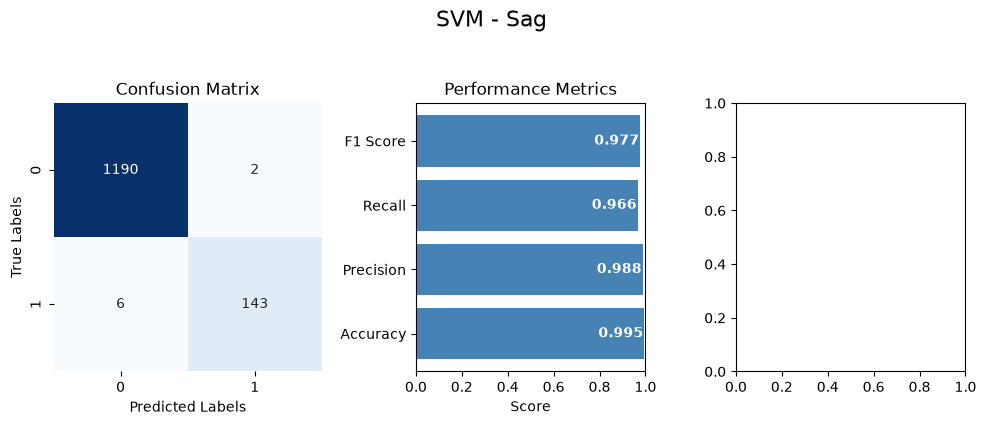

SVM - Sag_harmonics - Iterations: [440]


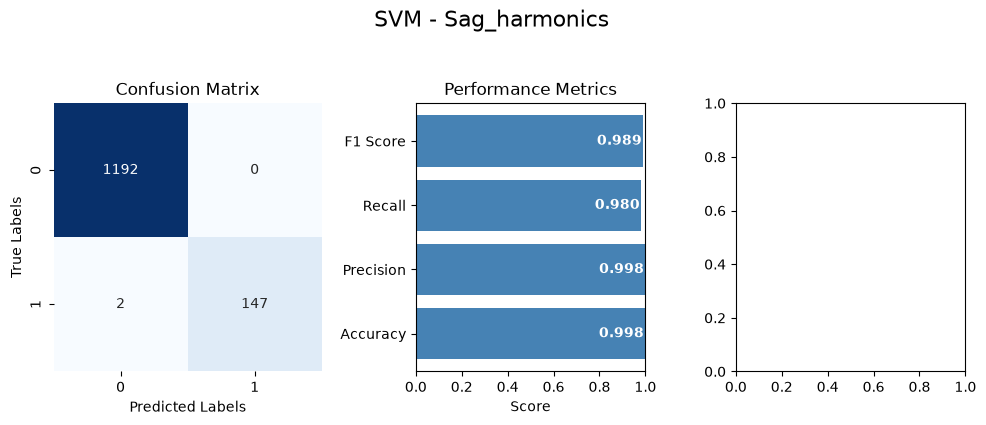

SVM - Transient - Iterations: [328]


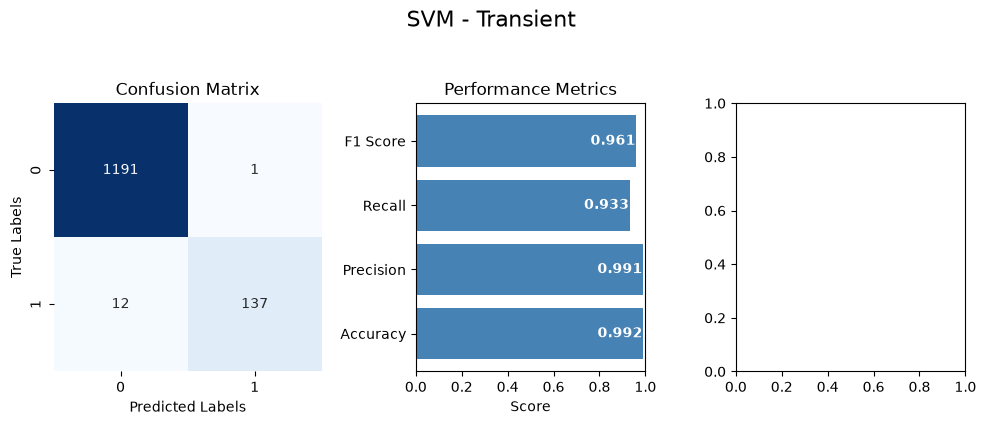

SVM - Swell_harmonics - Iterations: [653]


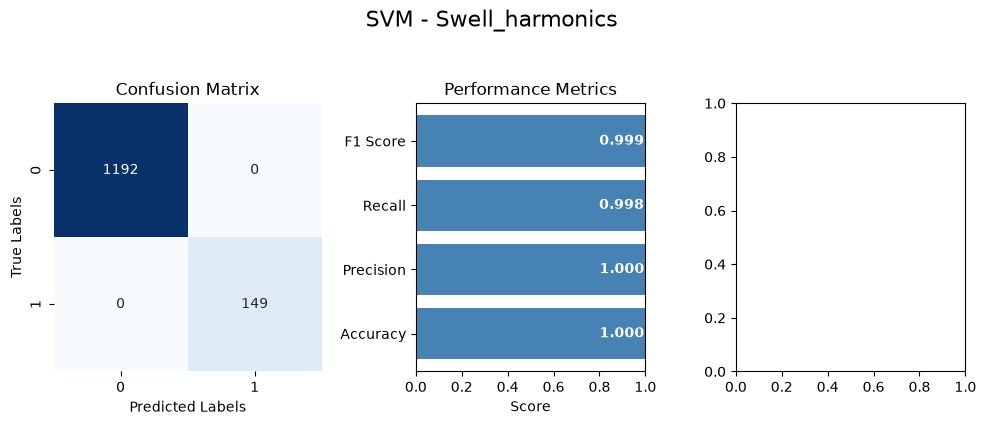

SVM - Normal - Iterations: [706]


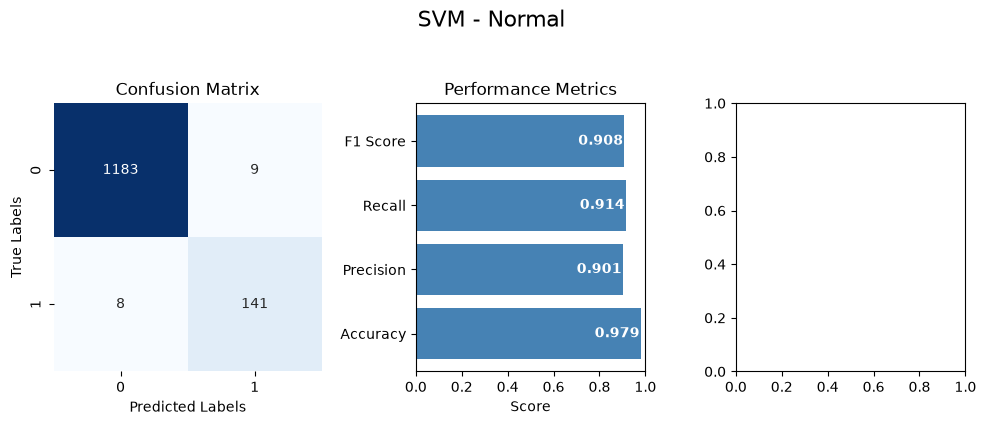

SVM - Flicker - Iterations: [1010]


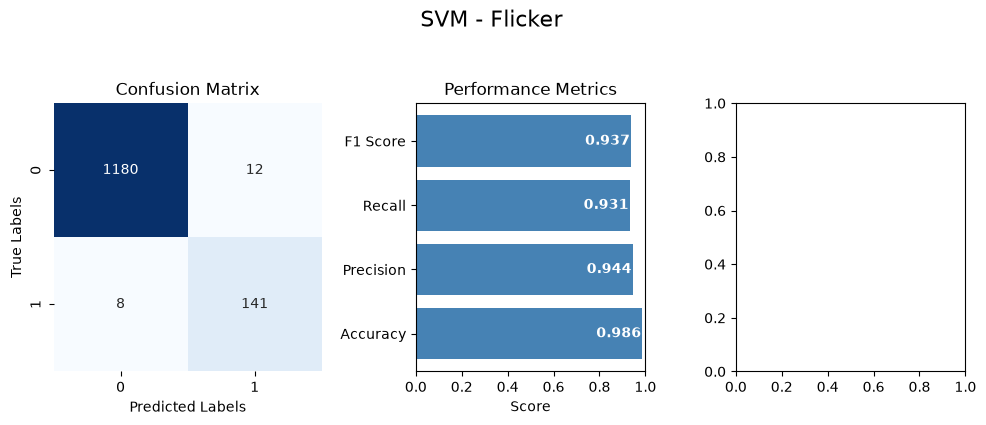

SVM - Harmonics - Iterations: [397]


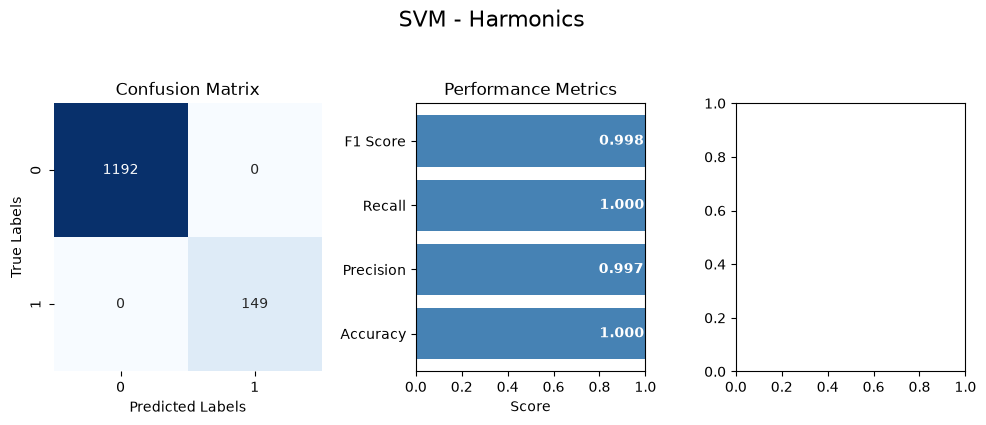

SVM - Swell - Iterations: [137]


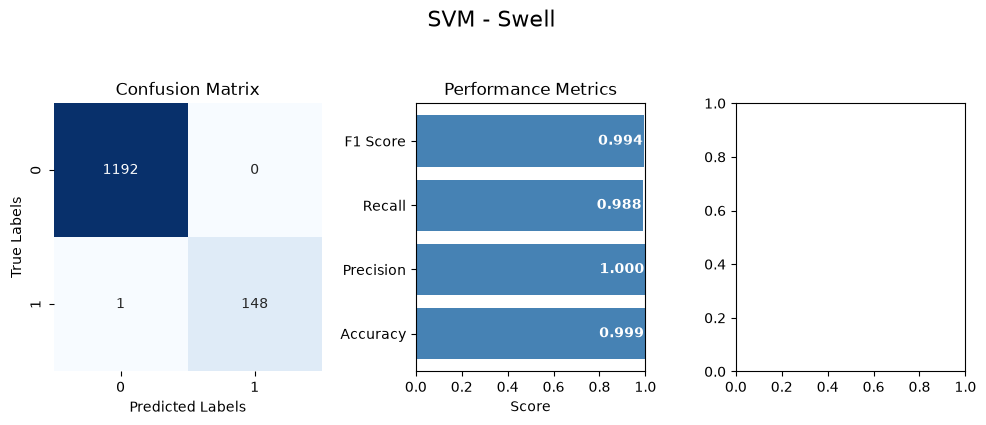

SVM - Interruption - Iterations: [292]


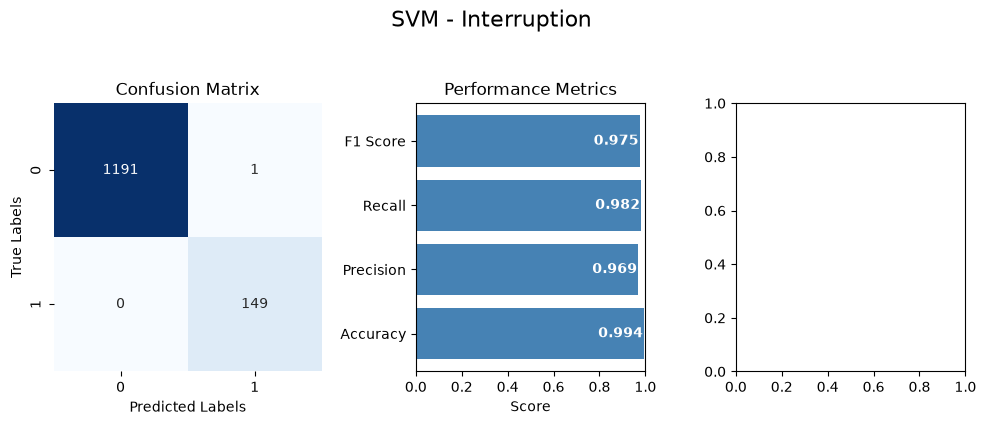

      Target Label  Accuracy  Precision    Recall  F1 Score
3  Swell_harmonics  0.999814   1.000000  0.998325  0.999160
6        Harmonics  0.999627   0.996667  1.000000  0.998325
7            Swell  0.998695   1.000000  0.988241  0.994067
1    Sag_harmonics  0.997576   0.998316  0.979891  0.988965
0              Sag  0.994966   0.988049  0.966415  0.977036
8     Interruption  0.994407   0.968625  0.981566  0.974995
2        Transient  0.991611   0.991124  0.932914  0.961073
5          Flicker  0.986204   0.944478  0.931230  0.937473
4           Normal  0.979306   0.900994  0.914438  0.907564
      Target Label  Accuracy  Precision    Recall  F1 Score
3  Swell_harmonics  1.000000   1.000000  1.000000  1.000000
6        Harmonics  1.000000   1.000000  1.000000  1.000000
8     Interruption  0.999254   0.996667  0.999581  0.998118
7            Swell  0.999254   0.999581  0.996644  0.998107
1    Sag_harmonics  0.998509   0.999162  0.993289  0.996203
0              Sag  0.994034   0.990595 

In [4]:
feature_sets = [ideal_features["Features to Use"].iloc[0], ideal_features["Features to Use"].iloc[1], ideal_features["Features to Use"].iloc[2], ideal_features["Features to Use"].iloc[3], ideal_features["Features to Use"].iloc[4], ideal_features["Features to Use"].iloc[5], ideal_features["Features to Use"].iloc[6], ideal_features["Features to Use"].iloc[7], ideal_features["Features to Use"].iloc[8]]

score_rows = []
score_rows_test = []

for target_label, features in zip(target_labels, feature_sets):
    data, sample_labels = data_import(files, features)
    full_data = pd.DataFrame(data, columns=features)

    # Change labels to binary classification: 1 for the target class, 0 for all other events
    binary_labels = [int(sample_label == target_label) for sample_label in sample_labels]

    # add labels to the dataframe
    full_data['Label'] = binary_labels

    X_train, X_test, y_train, y_test = train_test_split(data, binary_labels, test_size=0.2, random_state=12, stratify=binary_labels)
    

    metrics, metrics_test = Classifier(active_model, X_train, y_train, X_test, y_test, title="SVM - " + target_label)

    # Add the results to the score list
    score_rows.append({"Target Label": target_label, **metrics})
    score_rows_test.append({"Target Label": target_label, **metrics_test})

score_list = pd.DataFrame(score_rows)
# sort by F1 Score in descending order
score_list = score_list.sort_values(by='F1 Score', ascending=False)
print(score_list)

score_list_test = pd.DataFrame(score_rows_test)
# sort by F1 Score in descending order
score_list_test = score_list_test.sort_values(by='F1 Score', ascending=False)
print(score_list_test)